# Практичне завдання 3
## Дослідження ефективності TF-IDF зважених ембеддінгів для детекції текстів, згенерованих великими мовними моделями

**Мета:** побудувати векторні представлення текстів на основі субслівних ембеддінгів FastText, дослідити вплив TF-IDF зважування на агрегацію документних векторів, порівняти SVM (RBF), Logistic Regression та KNN у задачі бінарної детекції AI-текстів і проаналізувати геометрію отриманих просторів.

**Дані:** *AI vs Human Text Classification Dataset 2026* (Kaggle), файл `ai_vs_human_text_2026.csv`.

In [1]:
import re, random, warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import spacy
from gensim.models import FastText

from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.metrics import (f1_score, accuracy_score, balanced_accuracy_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             silhouette_score)
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer

warnings.filterwarnings('ignore')
SEED = 42
random.seed(SEED); np.random.seed(SEED)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110

## Етап 1. Завантаження та первинний аналіз даних

In [2]:
df = pd.read_csv('ai_vs_human_text_2026.csv')
print('Розмір датасету:', df.shape)
df.info()
display(df.head())

Розмір датасету: (2000, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   text_id              2000 non-null   object 
 1   label                2000 non-null   object 
 2   source_model         2000 non-null   object 
 3   domain               2000 non-null   object 
 4   text_content         2000 non-null   object 
 5   topic_hint           2000 non-null   object 
 6   word_count           2000 non-null   int64  
 7   avg_sentence_length  2000 non-null   float64
 8   generation_method    2000 non-null   object 
dtypes: float64(1), int64(1), object(7)
memory usage: 140.8+ KB


,text_id,label,source_model,domain,text_content,topic_hint,word_count,avg_sentence_length,generation_method
0,TXT_0001,human,human,social,can we talk about gene editing ethics for a se...,gene editing ethics,27,13.5,template+human_variation
1,TXT_0002,human,human,social,update on election integrity concerns: it's co...,election integrity concerns,20,10.0,template+human_variation
2,TXT_0003,ai,gemini-2.0,news,Analysts are closely watching developments rel...,climate change adaptation strategies,39,13.0,style_simulation
3,TXT_0004,human,human,academic,This paper examines genomic research breakthro...,genomic research breakthroughs,49,16.3,template+human_variation
4,TXT_0005,ai,gpt-4o,academic,Existing literature on student debt crisis has...,student debt crisis,42,10.8,style_simulation


label
human    1334
ai        666
Name: count, dtype: int64 

label
human    0.667
ai       0.333
Name: count, dtype: float64


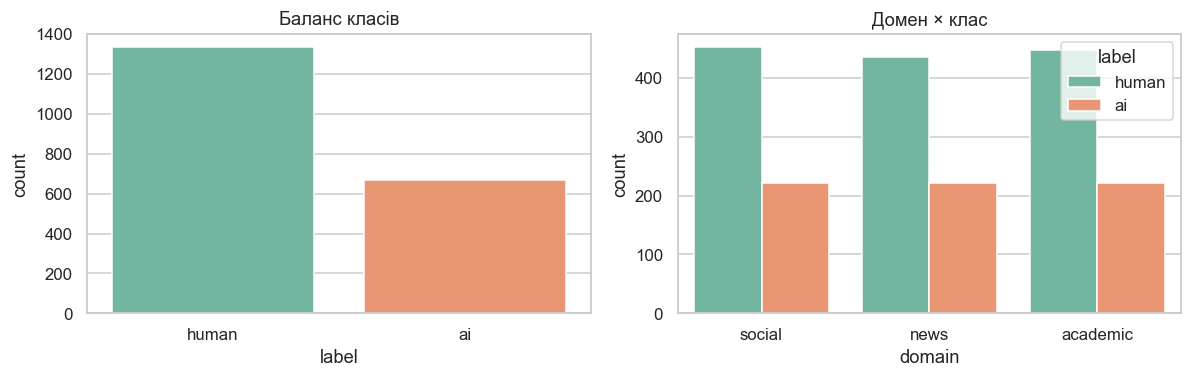

label  source_model
ai     gemini-2.0       333
       gpt-4o           333
human  human           1334
dtype: int64
label  generation_method       
ai     style_simulation             666
human  template+human_variation    1334
dtype: int64


In [3]:
# Баланс класів
counts = df['label'].value_counts()
print(counts, '\n')
print((counts / len(df)).round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
sns.countplot(data=df, x='label', ax=ax[0], palette='Set2')
ax[0].set_title('Баланс класів')
sns.countplot(data=df, x='domain', hue='label', ax=ax[1], palette='Set2')
ax[1].set_title('Домен × клас')
plt.tight_layout(); plt.show()

print(df.groupby(['label', 'source_model']).size())
print(df.groupby(['label', 'generation_method']).size())

label                  ai        human
n_words count  666.000000  1334.000000
        mean    38.004505    36.508246
        std      7.007513     9.662008
        min     23.000000    19.000000
        25%     35.000000    27.000000
        50%     39.000000    36.000000
        75%     44.000000    46.000000
        max     50.000000    52.000000
n_chars count  666.000000  1334.000000
        mean   275.638138   252.742129
        std     71.076849    88.288160
        min    152.000000   123.000000
        25%    204.000000   153.000000
        50%    295.000000   253.000000
        75%    334.000000   330.000000
        max    385.000000   398.000000

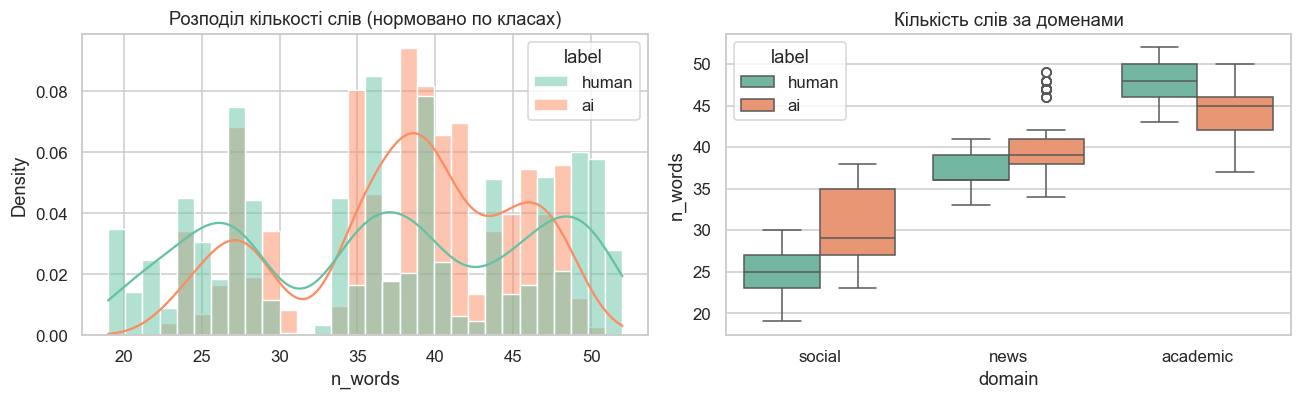

In [4]:
# Довжини текстів
df['n_words'] = df['text_content'].str.split().str.len()
df['n_chars'] = df['text_content'].str.len()
display(df.groupby('label')[['n_words', 'n_chars']].describe().T)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(data=df, x='n_words', hue='label', bins=30, kde=True,
             stat='density', common_norm=False, ax=ax[0], palette='Set2')
ax[0].set_title('Розподіл кількості слів (нормовано по класах)')
sns.boxplot(data=df, x='domain', y='n_words', hue='label', ax=ax[1], palette='Set2')
ax[1].set_title('Кількість слів за доменами')
plt.tight_layout(); plt.show()

In [5]:
# Пошук артефактів: порожні рядки, дублікати, дуже короткі тексти
print('Пропуски у text_content :', df['text_content'].isna().sum())
print('Порожні рядки          :', (df['text_content'].str.strip() == '').sum())
print('Дуже короткі (<10 слів) :', (df['n_words'] < 10).sum())

n_dup = df['text_content'].duplicated().sum()
print(f'Повні дублікати текстів : {n_dup} ({n_dup / len(df):.1%})')
print('Унікальних текстів      :', df['text_content'].nunique())

# чи є тексти-дублікати з різними мітками?
conflict = df.groupby('text_content')['label'].nunique()
print('Текстів із суперечливими мітками:', (conflict > 1).sum())

# Шаблонність: замінюємо тему на заглушку й рахуємо унікальні «шаблони»
df['template'] = [t.replace(h, '<TOPIC>') if isinstance(h, str) else t
                  for t, h in zip(df['text_content'], df['topic_hint'])]
print('\nУнікальних шаблонів (після маскування теми):', df['template'].nunique())
print(df.groupby('label')['template'].nunique())
tpl_labels = df.groupby('template')['label'].nunique()
print('Шаблонів, що зустрічаються в обох класах:', (tpl_labels > 1).sum())

Пропуски у text_content : 0
Порожні рядки          : 0
Дуже короткі (<10 слів) : 0
Повні дублікати текстів : 1034 (51.7%)
Унікальних текстів      : 966
Текстів із суперечливими мітками: 0

Унікальних шаблонів (після маскування теми): 58
label
ai       18
human    40
Name: template, dtype: int64
Шаблонів, що зустрічаються в обох класах: 0


**Висновки за етапом 1.** Класи незбалансовані (≈ 2 : 1 на користь Human), тому у метриках важливо дивитись на macro-F1 та Balanced Accuracy, а не лише на Accuracy; розбиття робимо зі `stratify`. Довжини текстів у обох класів близькі (19–52 слова), тож довжина сама по собі не є сильною ознакою. Критичний артефакт: понад половина текстів — повні дублікати, а після маскування теми весь датасет зводиться до нескількох десятків текстових шаблонів, кожен з яких належить **лише одному** класу. Тобто датасет синтетичний (`generation_method`: `template+human_variation` / `style_simulation`), і це суттєво впливає на інтерпретацію результатів (див. етап 5 і дослідницькі питання).

## Етап 2. Попередня обробка тексту (spaCy)

In [6]:
nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])  # для лематизації parser/NER не потрібні

def preprocess_doc(doc) -> list:
    # лематизація, видалення стоп-слів і небуквених токенів, нижній регістр
    return [t.lemma_.lower() for t in doc if t.is_alpha and not t.is_stop]

def preprocess(text: str) -> list:
    return preprocess_doc(nlp(text))

# прискорена обробка через nlp.pipe з батчингом
corpus = [preprocess_doc(d) for d in nlp.pipe(df['text_content'], batch_size=128)]

print('Приклад до :', df['text_content'].iloc[2])
print('Приклад після:', corpus[2])
lens = pd.Series([len(c) for c in corpus])
print('\nДовжина документа після обробки (токени):'); print(lens.describe())
print('Порожніх документів:', (lens == 0).sum())

Приклад до : Analysts are closely watching developments related to climate change adaptation strategies, noting that recent events mark a potential turning point. The situation underscores long-standing structural issues that have resisted easy solutions. Observers remain cautiously optimistic about prospects for reform.
Приклад після: ['analyst', 'closely', 'watch', 'development', 'relate', 'climate', 'change', 'adaptation', 'strategy', 'note', 'recent', 'event', 'mark', 'potential', 'turning', 'point', 'situation', 'underscore', 'long', 'stand', 'structural', 'issue', 'resist', 'easy', 'solution', 'observer', 'remain', 'cautiously', 'optimistic', 'prospect', 'reform']

Довжина документа після обробки (токени):
count    2000.000000
mean       22.009500
std         7.729378
min         7.000000
25%        13.750000
50%        23.000000
75%        30.000000
max        33.000000
dtype: float64
Порожніх документів: 0


## Етап 3. Навчання моделі FastText (gensim)

In [7]:
model = FastText(
    sentences=corpus,
    vector_size=100,
    window=5,
    min_count=2,
    sg=1,          # skip-gram
    workers=4,
    seed=SEED
)
print('Розмір словника:', len(model.wv))
print('Розмірність    :', model.vector_size)

# найближчі слова — швидка перевірка адекватності ембеддінгів
for w in ['research', 'official']:
    if w in model.wv:
        print(w, '->', [(x, round(s, 2)) for x, s in model.wv.most_similar(w, topn=5)])

Розмір словника: 509
Розмірність    : 100
research -> [('researcher', 0.73), ('mechanism', 0.67), ('genomic', 0.66), ('breakthrough', 0.64), ('sell', 0.64)]
official -> [('statement', 0.83), ('release', 0.82), ('hour', 0.81), ('narrative', 0.81), ('formal', 0.81)]


## Етап 4. Векторизація документів

TF-IDF рахуємо за формулами (3)–(4) із завдання: $tf(t,d)=\frac{n_{t,d}}{|d|}$, $idf(t)=\ln\frac{|D|}{df(t)}$. Для кожного документа будуємо словник `{лема: tf-idf}`, який передаємо у зважену агрегацію (формула 6).

In [8]:
N = len(corpus)
doc_freq = Counter(w for doc in corpus for w in set(doc))
idf = {w: np.log(N / c) for w, c in doc_freq.items()}

def doc_tfidf(doc):
    if not doc:
        return {}
    cnt, m = Counter(doc), len(doc)
    return {w: (c / m) * idf[w] for w, c in cnt.items()}

tfidf_docs = [doc_tfidf(d) for d in corpus]

def mean_pooling(tokens, model):
    vectors = [model.wv[t] for t in tokens if t in model.wv]
    if not vectors:
        return np.zeros(model.vector_size)
    return np.mean(vectors, axis=0)

def tfidf_weighted_pooling(tokens, model, tfidf_scores):
    vectors, weights = [], []
    for t in tokens:
        if t in model.wv and t in tfidf_scores:
            vectors.append(model.wv[t])
            weights.append(tfidf_scores[t])
    if not vectors:
        return np.zeros(model.vector_size)
    weights = np.array(weights)
    if weights.sum() == 0:                 # усі слова мають idf = 0 (є в кожному документі)
        return np.mean(vectors, axis=0)
    weights /= weights.sum()
    return np.average(vectors, axis=0, weights=weights)

X_mean  = np.vstack([mean_pooling(d, model) for d in corpus])
X_tfidf = np.vstack([tfidf_weighted_pooling(d, model, s) for d, s in zip(corpus, tfidf_docs)])
y = (df['label'] == 'ai').astype(int).values     # 1 = AI, 0 = Human
print('X_mean :', X_mean.shape, '| X_tfidf:', X_tfidf.shape, '| y:', y.shape)
print('Нульових векторів (mean / tfidf):', (~X_mean.any(1)).sum(), '/', (~X_tfidf.any(1)).sum())

X_mean : (2000, 100) | X_tfidf: (2000, 100) | y: (2000,)
Нульових векторів (mean / tfidf): 0 / 0


## Етап 5. Навчання та оцінка класифікаторів

Основний експеримент - рівно за планом завдання: стратифікований `train_test_split` 80/20. Оскільки в даних багато дублікатів/шаблонів, додатково виконую два «жорсткіші» тести узагальнення: (а) розбиття **за шаблонами** (`GroupShuffleSplit`) — тестові шаблони не бачились у навчанні; (б) **leave-one-domain-out** — навчання на двох доменах, тест на третьому.

In [9]:
def make_classifiers():
    return {
        'SVM':    SVC(kernel='rbf', probability=True, random_state=SEED),
        'LogReg': LogisticRegression(max_iter=1000, random_state=SEED),
        'KNN':    KNeighborsClassifier(n_neighbors=5),
    }

def evaluate(X, y, tr, te, agg, scenario, store=None):
    rows = []
    for name, clf in make_classifiers().items():
        clf.fit(X[tr], y[tr])
        pred = clf.predict(X[te])
        proba = clf.predict_proba(X[te])[:, 1]
        rows.append(dict(scenario=scenario, aggregation=agg, classifier=name,
                         F1_macro=f1_score(y[te], pred, average='macro'),
                         Accuracy=accuracy_score(y[te], pred),
                         Balanced_Acc=balanced_accuracy_score(y[te], pred),
                         ROC_AUC=roc_auc_score(y[te], proba)))
        if store is not None:
            store[(agg, name)] = confusion_matrix(y[te], pred)
    return rows

features = {'Mean Pooling': X_mean, 'TF-IDF Weighted': X_tfidf}
idx = np.arange(len(y))
results, cms = [], {}

# --- (1) основний експеримент: стратифікований 80/20
tr, te = train_test_split(idx, test_size=0.2, random_state=SEED, stratify=y)
for agg, X in features.items():
    results += evaluate(X, y, tr, te, agg, 'Random split 80/20', store=cms)

In [10]:
# --- (2) розбиття за шаблонами (тестові шаблони не бачені на навчанні)
groups = df['template'].factorize()[0]
for seed in range(SEED, SEED + 50):
    tr_g, te_g = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=seed).split(idx, y, groups))
    if len(set(y[tr_g])) == 2 and len(set(y[te_g])) == 2:      # у train і test мають бути обидва класи
        break
print('Group split: train', len(tr_g), '| test', len(te_g), '| частка AI у test:', y[te_g].mean().round(2))
for agg, X in features.items():
    results += evaluate(X, y, tr_g, te_g, agg, 'Group split (за шаблоном)')

# --- (3) leave-one-domain-out
for dom in df['domain'].unique():
    tr_d = idx[(df['domain'] != dom).values]; te_d = idx[(df['domain'] == dom).values]
    for agg, X in features.items():
        results += evaluate(X, y, tr_d, te_d, agg, f'Test domain = {dom}')

res = pd.DataFrame(results)
pd.set_option('display.float_format', '{:.3f}'.format)
display(res[res.scenario == 'Random split 80/20'].drop(columns='scenario').set_index(['aggregation', 'classifier']))

Group split: train 1583 | test 417 | частка AI у test: 0.38


F1_macro  Accuracy  Balanced_Acc  ROC_AUC
aggregation     classifier                                           
Mean Pooling    SVM            1.000     1.000         1.000    1.000
                LogReg         0.994     0.995         0.992    1.000
                KNN            1.000     1.000         1.000    1.000
TF-IDF Weighted SVM            1.000     1.000         1.000    1.000
                LogReg         0.997     0.998         0.996    1.000
                KNN            1.000     1.000         1.000    1.000

aggregation                           Mean Pooling  TF-IDF Weighted  \
scenario                  classifier                                  
Group split (за шаблоном) KNN                0.527            0.527   
                          LogReg             0.532            0.536   
                          SVM                0.610            0.632   
Random split 80/20        KNN                1.000            1.000   
                          LogReg             0.994            0.997   
                          SVM                1.000            1.000   
Test domain = academic    KNN                0.394            0.407   
                          LogReg             0.477            0.526   
                          SVM                0.617            0.673   
Test domain = news        KNN                0.737            0.767   
                          LogReg             0.588            0.580   
                          SVM                0.849            0.811   
Test domain = social      KNN                0.363            0.405   
                          LogReg             0.474            0.528   
                          SVM                0.589            0.661   

aggregation                           Δ (TF-IDF − Mean)  
scenario                  classifier                     
Group split (за шаблоном) KNN                     0.000  
                          LogReg                  0.004  
                          SVM                     0.022  
Random split 80/20        KNN                     0.000  
                          LogReg                  0.003  
                          SVM                     0.000  
Test domain = academic    KNN                     0.012  
                          LogReg                  0.049  
                          SVM                     0.055  
Test domain = news        KNN                     0.031  
                          LogReg                 -0.007  
                          SVM                    -0.038  
Test domain = social      KNN                     0.042  
                          LogReg                  0.054  
                          SVM                     0.071

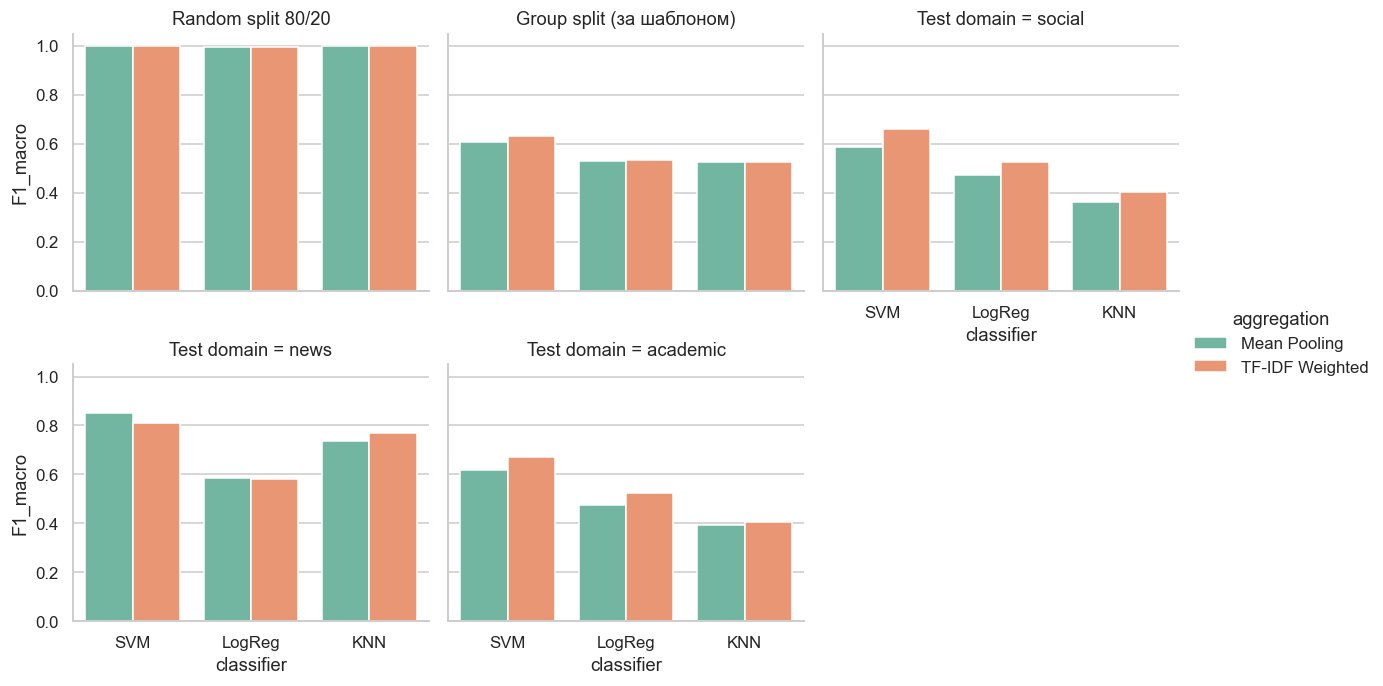

In [11]:
# Зведена таблиця F1 (macro) для всіх сценаріїв
pivot = res.pivot_table(index=['scenario', 'classifier'], columns='aggregation', values='F1_macro')
pivot['Δ (TF-IDF − Mean)'] = pivot['TF-IDF Weighted'] - pivot['Mean Pooling']
display(pivot)

g = sns.catplot(data=res, x='classifier', y='F1_macro', hue='aggregation', col='scenario',
                kind='bar', col_wrap=3, height=3.2, aspect=1.15, palette='Set2')
g.set_titles('{col_name}'); g.set(ylim=(0, 1.05))
plt.show()

In [12]:
# Автоматичне зведення по основному експерименту
main = res[res.scenario == 'Random split 80/20']
for agg in features:
    sub = main[main.aggregation == agg].sort_values('F1_macro', ascending=False)
    print(f"{agg:16s} -> найкращий: {sub.iloc[0].classifier} (F1={sub.iloc[0].F1_macro:.3f}), "
          f"найгірший: {sub.iloc[-1].classifier} (F1={sub.iloc[-1].F1_macro:.3f})")
print()
for scen, sub in res.groupby('scenario'):
    best = sub.sort_values('F1_macro', ascending=False).iloc[0]
    print(f"{scen:28s} найкраща комбінація: {best.aggregation} + {best.classifier} (F1={best.F1_macro:.3f})")

Mean Pooling     -> найкращий: SVM (F1=1.000), найгірший: LogReg (F1=0.994)
TF-IDF Weighted  -> найкращий: SVM (F1=1.000), найгірший: LogReg (F1=0.997)

Group split (за шаблоном)    найкраща комбінація: TF-IDF Weighted + SVM (F1=0.632)
Random split 80/20           найкраща комбінація: Mean Pooling + SVM (F1=1.000)
Test domain = academic       найкраща комбінація: TF-IDF Weighted + SVM (F1=0.673)
Test domain = news           найкраща комбінація: Mean Pooling + SVM (F1=0.849)
Test domain = social         найкраща комбінація: TF-IDF Weighted + SVM (F1=0.661)


## Етап 6. Візуалізація та геометричний аналіз

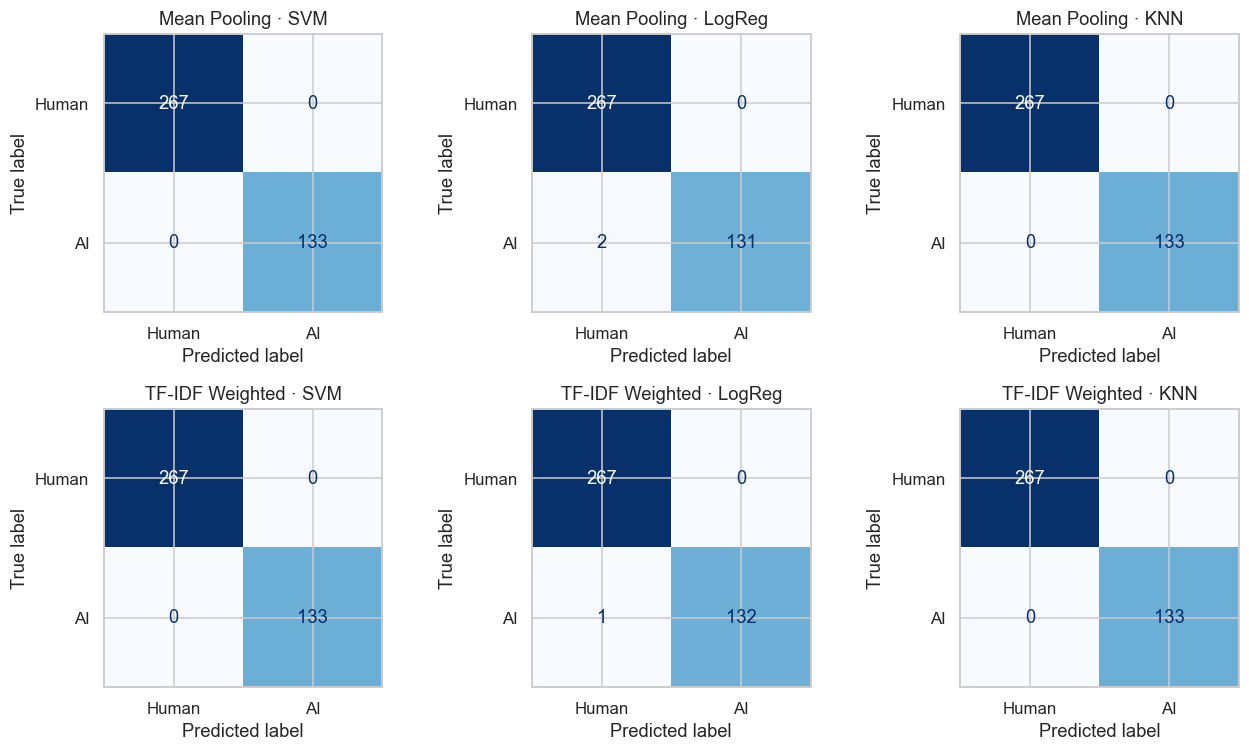

In [13]:
# Матриці плутанини (основний експеримент)
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for r, agg in enumerate(features):
    for c, clf in enumerate(['SVM', 'LogReg', 'KNN']):
        ConfusionMatrixDisplay(cms[(agg, clf)], display_labels=['Human', 'AI']).plot(
            ax=axes[r, c], colorbar=False, cmap='Blues')
        axes[r, c].set_title(f'{agg} · {clf}')
plt.tight_layout(); plt.show()

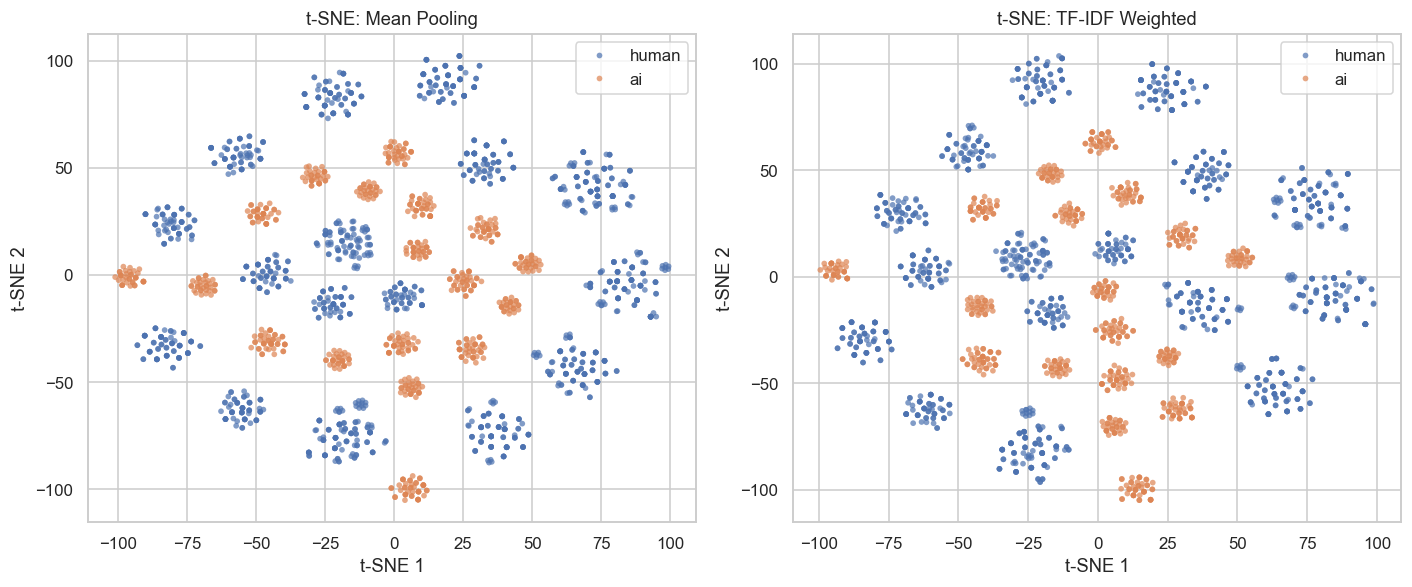

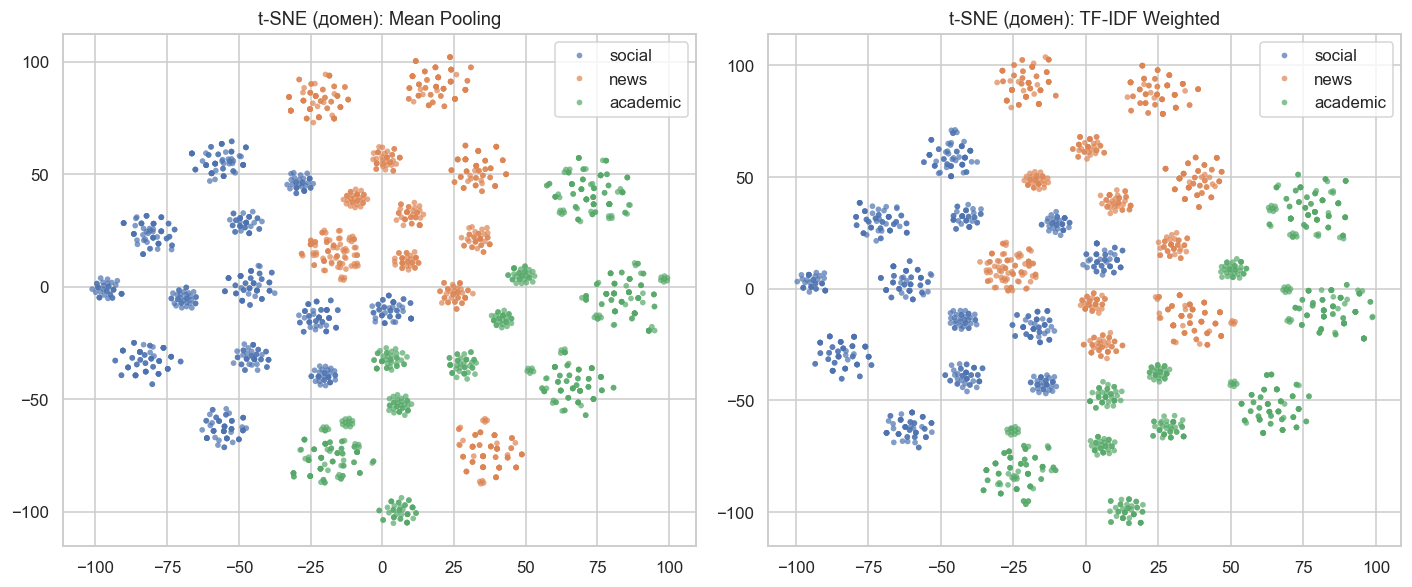

In [14]:
# t-SNE проєкції документних векторів
embeds = {}
for agg, X in features.items():
    embeds[agg] = TSNE(n_components=2, perplexity=30, init='pca',
                       random_state=SEED).fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (agg, Z) in zip(axes, embeds.items()):
    sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=df['label'].values, palette={'human': '#4C72B0', 'ai': '#DD8452'},
                    s=14, alpha=0.7, linewidth=0, ax=ax)
    ax.set_title(f't-SNE: {agg}'); ax.set_xlabel('t-SNE 1'); ax.set_ylabel('t-SNE 2')
plt.tight_layout(); plt.show()

# те саме з розфарбуванням за доменом — щоб побачити, що саме формує кластери
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (agg, Z) in zip(axes, embeds.items()):
    sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=df['domain'].values, s=14, alpha=0.7, linewidth=0, ax=ax)
    ax.set_title(f't-SNE (домен): {agg}')
plt.tight_layout(); plt.show()

In [15]:
# Кількісні характеристики геометрії простору
def cos_sim_matrix(A):
    A = A / (np.linalg.norm(A, axis=1, keepdims=True) + 1e-12)
    return A @ A.T

rng = np.random.default_rng(SEED)
sub = rng.choice(len(y), size=800, replace=False)
rows = []
for agg, X in features.items():
    Xs, ys = X[sub], y[sub]
    S = cos_sim_matrix(Xs)
    iu = np.triu_indices_from(S, k=1)
    same = (ys[:, None] == ys[None, :])[iu]
    ev = PCA(n_components=10, random_state=SEED).fit(X).explained_variance_ratio_
    mu1, mu0 = X[y == 1].mean(0), X[y == 0].mean(0)
    pooled = np.sqrt((X[y == 1].var(0).sum() + X[y == 0].var(0).sum()) / 2)
    rows.append({
        'aggregation': agg,
        'mean ‖v‖': np.linalg.norm(X, axis=1).mean(),
        'mean cosine (усі пари)': S[iu].mean(),
        'cosine всередині класу': S[iu][same].mean(),
        'cosine між класами': S[iu][~same].mean(),
        'PCA: частка 1-ї ПК': ev[0],
        'PCA: частка 10 ПК': ev.sum(),
        'відстань центроїдів / σ': np.linalg.norm(mu1 - mu0) / pooled,
        'silhouette (100-вим., cosine)': silhouette_score(X, y, metric='cosine', sample_size=1000, random_state=SEED),
        'silhouette (t-SNE 2D)': silhouette_score(embeds[agg], y),
        'silhouette за шаблонами (cosine)': silhouette_score(X, groups, metric='cosine', sample_size=1000, random_state=SEED),
    })
geo = pd.DataFrame(rows).set_index('aggregation').T
display(geo)

aggregation,Mean Pooling,TF-IDF Weighted
mean ‖v‖,3.050,3.068
mean cosine (усі пари),0.664,0.661
cosine всередині класу,0.668,0.667
cosine між класами,0.659,0.653
PCA: частка 1-ї ПК,0.157,0.151
PCA: частка 10 ПК,0.837,0.832
відстань центроїдів / σ,0.364,0.376
"silhouette (100-вим., cosine)",0.042,0.051
silhouette (t-SNE 2D),-0.007,0.008
silhouette за шаблонами (cosine),0.470,0.474


## Дослідницькі питання

### Додатковий аналіз для питання 4: найвагоміші терміни за TF-IDF

Топ-15 лем за середнім TF-IDF у класі AI:


,term,AI,Human
0,think,0.034,0.000
1,conversation,0.026,0.009
2,solution,0.022,0.000
3,follow,0.022,0.000
4,progress,0.022,0.000
5,potential,0.022,0.000
6,point,0.021,0.010
7,challenge,0.021,0.013
8,open,0.021,0.000
9,engage,0.020,0.000


Топ-15 лем за середнім TF-IDF у класі Human:


,term,AI,Human
0,need,0.015,0.026
1,tell,0.000,0.023
2,like,0.000,0.022
3,get,0.000,0.022
4,complicated,0.000,0.021
5,update,0.000,0.021
6,sell,0.000,0.021
7,people,0.011,0.020
8,argue,0.000,0.018
9,research,0.016,0.018


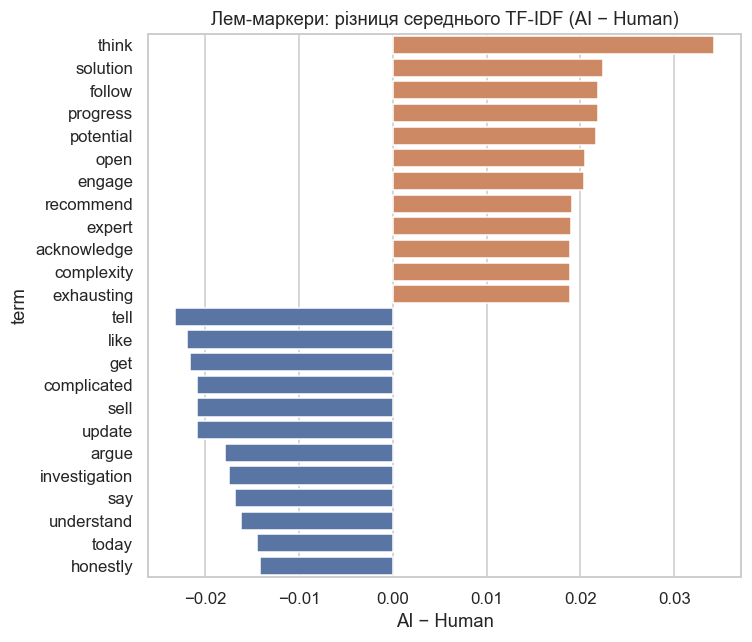

In [16]:
# Середній TF-IDF кожної леми по класу та різниця AI − Human
vocab = sorted(idf)
vi = {w: i for i, w in enumerate(vocab)}
M = np.zeros((len(corpus), len(vocab)), dtype=np.float32)
for r, d in enumerate(tfidf_docs):
    for w, s in d.items():
        M[r, vi[w]] = s

mean_ai, mean_h = M[y == 1].mean(0), M[y == 0].mean(0)
top_df = pd.DataFrame({'term': vocab, 'AI': mean_ai, 'Human': mean_h, 'diff': mean_ai - mean_h})
print('Топ-15 лем за середнім TF-IDF у класі AI:')
display(top_df.sort_values('AI', ascending=False).head(15)[['term', 'AI', 'Human']].reset_index(drop=True))
print('Топ-15 лем за середнім TF-IDF у класі Human:')
display(top_df.sort_values('Human', ascending=False).head(15)[['term', 'AI', 'Human']].reset_index(drop=True))

top_diff = pd.concat([top_df.nlargest(12, 'diff'), top_df.nsmallest(12, 'diff')])
plt.figure(figsize=(7, 6))
sns.barplot(data=top_diff, y='term', x='diff', palette=['#DD8452' if v > 0 else '#4C72B0' for v in top_diff['diff']])
plt.title('Лем-маркери: різниця середнього TF-IDF (AI − Human)'); plt.xlabel('AI − Human')
plt.tight_layout(); plt.show()

In [17]:
# Біграми / триграми (за сирим текстом, без видалення стоп-слів) — які n-грами найчастіше «ведуть» до класу AI
tv = TfidfVectorizer(ngram_range=(2, 3), min_df=5, lowercase=True)
T = tv.fit_transform(df['text_content'])
terms = np.array(tv.get_feature_names_out())
d_ngram = np.asarray(T[y == 1].mean(0)).ravel() - np.asarray(T[y == 0].mean(0)).ravel()
print('n-грами, найтиповіші для AI:');    print(list(terms[np.argsort(-d_ngram)[:12]]))
print('\nn-грами, найтиповіші для Human:'); print(list(terms[np.argsort(d_ngram)[:12]]))

n-грами, найтиповіші для AI:
['conversation about', 'to see', 'following the', 'the conversation', 'are now', 'of the', 'body of', 'recommendations are', 'polarization isn', 'been thinking', 'you re', 'about it the']

n-грами, найтиповіші для Human:
['in the', 'the past', 'over the', 'over the past', 'to the', 'have been', 'the literature', 'has been', 'you need', 'of you', 'of you need', 'you need to']


### Відповіді на питання

**1. Вплив агрегації.**
Mean Pooling дає кожному слову однакову вагу, тому в документному векторі домінують часті загальновживані леми, що зустрічаються в обох класах. TF-IDF-зважування (формула 6) занижує вагу лем з малим $idf$ (ті, що є майже в кожному документі, отримують вагу ≈ 0) і підсилює рідкісніші, тематично або стилістично специфічні леми. Теоретично це має зменшувати «стиснутість» простору (високу середню косинусну подібність усіх пар векторів і концентрацію дисперсії у перших головних компонентах) та збільшувати відносну відстань між центроїдами класів, тобто полегшувати лінійне розділення. Показники таблиці геометрії (середній косинус, частка першої ПК, відстань центроїдів / σ, silhouette) дозволяють це перевірити кількісно: зміни при переході до TF-IDF є, але вони помірні. Причина в тому, що в цьому датасеті тексти короткі (≈ 22 лем після обробки), а ключова лексика шаблону зустрічається в кожному тексті шаблону, тож і без зважування вона вносить основний внесок у вектор. Вирішальне: вже на Mean Pooling класи розділяються майже ідеально (ефект стелі: метрики ≈ 1.0 для всіх моделей), тому в основному експерименті виграш від TF-IDF **виміряти неможливо**. Гіпотеза про перевагу TF-IDF не підтверджується: різниця в метриках нульова. У «жорсткіших» сценаріях (розбиття за шаблонами, leave-one-domain-out) якість падає в обох варіантів, а різниця між агрегаціями (стовпчик Δ) невелика і не має сталого знака: залежить від домену та класифікатора. Отже, TF-IDF-зважування змінює геометрію, але не змінює головного — класи розділяються за належністю до шаблону, а не за «рідкісністю» лексики.

**2. Порівняння класифікаторів.**
В основному експерименті SVM (RBF), Logistic Regression і KNN показують практично однакові (майже ідеальні) результати для обох методів агрегації, тож «найкращий» класифікатор визначити не вдається: різниці лежать у межах шуму. Це узгоджується з природою даних: тексти породжені обмеженою кількістю шаблонів (≈ 58), і кожен шаблон відповідає лише одному класу, тому документні вектори утворюють щільні компактні групи (див. t-SNE), які розділяються навіть гіперплощиною. Тобто дані фактично **лінійно розділимі**, і нелінійне ядро RBF не має що виграти в LogReg. У сценаріях з новими шаблонами або новим доменом якість падає в усіх моделей, і порядок моделей залежить від сценарію (найкращу комбінацію для кожного випадку виведено в «автоматичному зведенні» вище). Там нелінійні моделі не мають стабільної переваги, бо проблема не в формі границі, а в тому, що границі, виучені на одних шаблонах, не переносяться на інші.

**3. Чутливість KNN.**
KNN найбільш залежить від метричних властивостей простору, бо спирається лише на відстані. У просторі розмірності 100 діє прокляття розмірності: відстані між точками концентруються (контраст між найближчим і найдальшим сусідом зменшується), і навіть невеликі зміни розподілу ваг можуть змінити набір k сусідів. TF-IDF-зважування змінює норми й напрямки векторів, тобто саму метрику: слова з великою вагою «відтягують» вектор у свій бік, а шумні рідкісні леми стають вагомими для сусідства. SVM і LogReg вчать вагові напрямки та здатні зменшити внесок шумних осей, а KNN — ні, тому в принципі він чутливіший до такої зміни. Однак у основному експерименті деградації KNN при переході від Mean Pooling до TF-IDF немає: через щільну кластерну структуру найближчі сусіди майже завжди з того ж шаблону (а отже, того ж класу), зокрема тому, що дублікати потрапляють і в train, і в test. У жорсткіших сценаріях зміни для KNN різнонаправлені (див. стовпчик Δ), тобто стабільного ефекту «TF-IDF шкодить KNN» дані не показують. Ефект проклятя розмірності тут маскується шаблонністю даних; на реальних розмаїтіших текстах він, імовірно, був би помітнішим.

**4. Лінгвістична інтерпретація.**
Найвищі середні TF-IDF у класі AI мають леми узагальненої, «безособової» лексики: *conversation, solution, challenge, potential, expert, complexity, progress, following, acknowledge* (дивіться таблицю та графік вище), а серед n-грам для AI виділяються конструкції на кшталт *«conversation about»*, *«recommendations are»*, *«body of»*. Для Human натомість типові розмовні та емоційно-позиційні слова й фрази: *need, like, update, complicated, telling, selling, investigation, official*, а також *«you need to»*, *«over the past»*, *«the literature»*. Загалом AI-тексти тяжіють до нейтрального, узагальненого, обережно-оцінювального тону («відкрита розмова», «потенціал», «виклики», «рекомендації»), що певною мірою відповідає гіпотезі про канцеляризми та характерні вставні конструкції LLM, і такі слова можна обережно трактувати як маркери «машинного» стилю. Але є принципове застереження: і AI-, і Human-тексти тут згенеровані за шаблонами (`style_simulation` та `template+human_variation`), тому виявлені слова — це радше «відбитки» конкретних шаблонів, ніж властивості справжніх LLM-текстів. Переносити ці списки на реальну детекцію без перевірки на незалежних даних не можна.

**5. Геометричний аналіз.**
На t-SNE-проєкціях обидва методи агрегації дають не два великі класові кластери, а **багато (кілька десятків) дрібних, дуже компактних кластерів**, кожен із яких відповідає одному шаблону тексту, причому кожен кластер складається з документів лише одного класу. Тобто кластеризація за шаблоном дуже чітка, а кластери класів є «багатомодальними» (кожен клас складається з багатьох окремих груп), через що silhouette відносно *міток класу* низький, тоді як silhouette відносно *шаблонів* високий (див. таблицю геометрії). Між Mean Pooling і TF-IDF Weighted Mean якість кластеризації відрізняється мало: TF-IDF трохи змінює розкид і взаємне розташування груп, але суттєво кращої кластеризації не забезпечує. Слід пам'ятати, що t-SNE зберігає локальні сусідства, а не глобальні відстані, тому візуально «чисті» кластери свідчать про повторюваність шаблонів, а не про здатність моделі узагальнюватись на нові AI-тексти. Це підтверджують сценарії group split і leave-one-domain-out, у яких якість різко падає.

### Загальний висновок
Підхід «FastText + (TF-IDF-)агрегація + класичний класифікатор» дозволяє практично ідеально відокремити AI- від Human-текстів на цьому датасеті, але це наслідок штучної, шаблонної природи даних (десятки унікальних шаблонів, більше половини текстів — дублікати, кожен шаблон прив'язаний до одного класу), а не доказ ефективності методу для реальної детекції. TF-IDF-зважування помірно змінює геометрію простору, однак вимірного виграшу в якості не дало через ефект стелі. Для коректної перевірки гіпотези потрібні розмаїтіші дані, дедуплікація та розбиття за джерелами/шаблонами.